# 11 — Sentinel-1 vật lý: góc tới, lọc và ngưỡng

Notebook này kiểm tra dữ liệu và 50 so sánh **ứng viên trên validation**.
Chưa phải chất lượng pipeline sau phân lớp. SOS vẫn là benchmark chính;
Cantarell bổ sung bức xạ vật lý và gió có tọa độ/thời điểm.

Chia theo nhóm cảnh và liên kết đối tượng: 94 train / 35 validation / 25 test
sau các chốt chất lượng. Dầu tràn và dầu thấm tự nhiên cùng thuộc foreground.
Không gán dầu thấm thành look-alike. Gió chỉ cung cấp bối cảnh.

Code nguồn: `scripts/cantarell_pipeline.py`, `scripts/screen_cantarell.py`.
Notebook đọc bằng chứng đã lưu, kiểm tra hash và chạy lại một ví dụ validation;
không huấn luyện lại, không sử dụng test, không tự tải dữ liệu.


In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/sar_oil').is_dir())
sys.path.insert(0, str(ROOT/'scripts'))
from cantarell_experiment_data import load_manifest, load_input, sha, MANIFEST
from cantarell_pipeline import candidates, normalize_power
from sar_oil.evaluation import counts, summarize
manifest, protocol = load_manifest()
screen = json.loads((ROOT/'results/cantarell/screen.json').read_text())
assert screen['complete'] and len(screen['comparisons']) == 50
assert screen['binding']['manifest_sha256'] == sha(MANIFEST)
assert screen['binding']['script_sha256'] == sha(ROOT/'scripts/screen_cantarell.py')
assert screen['binding']['operator_sha256'] == sha(ROOT/'scripts/cantarell_pipeline.py')
assert not screen['test_accessed']
print('Eligible samples:', manifest['counts'])
display(pd.DataFrame(manifest['excluded']))


Eligible samples: {'train': 94, 'test': 25, 'val': 35}


,sample,split,checks,detail
0,IMG_02_TILE_009,train,[metadata_support_or_geolocation],Outside metadata/interpolation support: latitude
1,IMG_04_TILE_009,train,[metadata_support_or_geolocation],Outside metadata/interpolation support: latitude
2,IMG_05_TILE_006,train,[metadata_support_or_geolocation],Outside metadata/interpolation support: latitude
3,IMG_09_TILE_006,train,[metadata_support_or_geolocation],Outside metadata/interpolation support: latitude
4,IMG_10_TILE_006,train,[metadata_support_or_geolocation],Outside metadata/interpolation support: latitude
5,IMG_12_TILE_003,val,[pearson],NaN
6,IMG_12_TILE_007,val,[pearson],NaN
7,IMG_12_TILE_011,val,[metadata_support_or_geolocation],Outside metadata/interpolation support: latitude
8,IMG_12_TILE_014,val,[pearson],NaN
9,IMG_17_TILE_006,test,[metadata_support_or_geolocation],Outside metadata/interpolation support: latitude


## Kiểm tra lại toàn bộ số đếm và bảng xếp hạng

F1 mức đối tượng ghép một-một tại IoU ≥0,5. Không loại GT nhỏ theo diện tích
ứng viên. Mọi cấu hình giữ min_area=64 và không xử lý hình thái.
Lưới hữu hạn này không phải định lý chứng minh Lee hoặc Niblack luôn tốt nhất.


In [2]:
rows = []
validation_ids = {r['sample'] for r in manifest['samples'] if r['split']=='val'}
for c in screen['comparisons']:
    assert {r['sample'] for r in c['rows']} == validation_ids
    for backend in ['numpy','reference']:
        assert summarize([r['counts'][backend] for r in c['rows']]) == c['summary'][backend]
    rows.append({'branch':c['branch'], 'config':c['config_id'],
                 'filter':str(c['config']['filter']), 'threshold':str(c['config']['threshold']),
                 'precision':c['summary']['numpy']['precision'],
                 'recall':c['summary']['numpy']['recall'], 'f1':c['summary']['numpy']['f1'],
                 'reference_f1':c['summary']['reference']['f1'],
                 'different_pixels':c['mask_disagreement_pixels']})
table = pd.DataFrame(rows)
display(table.sort_values(['branch','f1'], ascending=[True,False]))
print('Total differing candidate pixels:', table.different_pixels.sum())
print('Retained candidate IDs:', screen['retained_candidate_ids'])


,branch,config,filter,threshold,precision,recall,f1,reference_f1,different_pixels
45,gamma0,20,"{'name': 'lee', 'size': 7, 'looks': 4}",{'name': 'otsu'},0.016605,0.062572,0.026245,0.026245,0
35,gamma0,10,"{'name': 'median', 'size': 7}",{'name': 'otsu'},0.015123,0.066049,0.024611,0.024611,0
30,gamma0,5,"{'name': 'mean', 'size': 7}",{'name': 'otsu'},0.014930,0.054461,0.023436,0.023436,0
40,gamma0,15,"{'name': 'lee', 'size': 7, 'looks': 1}",{'name': 'otsu'},0.014308,0.053302,0.022560,0.022560,0
27,gamma0,2,{'name': 'none'},"{'name': 'niblack', 'size': 31, 'k': 0.5}",0.007751,0.106605,0.014452,0.014452,0
29,gamma0,4,{'name': 'none'},"{'name': 'niblack', 'size': 51, 'k': 0.5}",0.007708,0.104287,0.014355,0.014355,0
47,gamma0,22,"{'name': 'lee', 'size': 7, 'looks': 4}","{'name': 'niblack', 'size': 31, 'k': 0.5}",0.003687,0.079954,0.007049,0.007049,0
32,gamma0,7,"{'name': 'mean', 'size': 7}","{'name': 'niblack', 'size': 31, 'k': 0.5}",0.003587,0.077636,0.006856,0.006856,0
42,gamma0,17,"{'name': 'lee', 'size': 7, 'looks': 1}","{'name': 'niblack', 'size': 31, 'k': 0.5}",0.003585,0.077636,0.006854,0.006854,0
38,gamma0,13,"{'name': 'median', 'size': 7}","{'name': 'niblack', 'size': 51, 'k': 0.2}",0.003558,0.037080,0.006493,0.006493,0


Total differing candidate pixels: 0
Retained candidate IDs: {'sigma0': [2, 4, 5, 10, 20, 22], 'gamma0': [2, 4, 5, 10, 20, 22]}


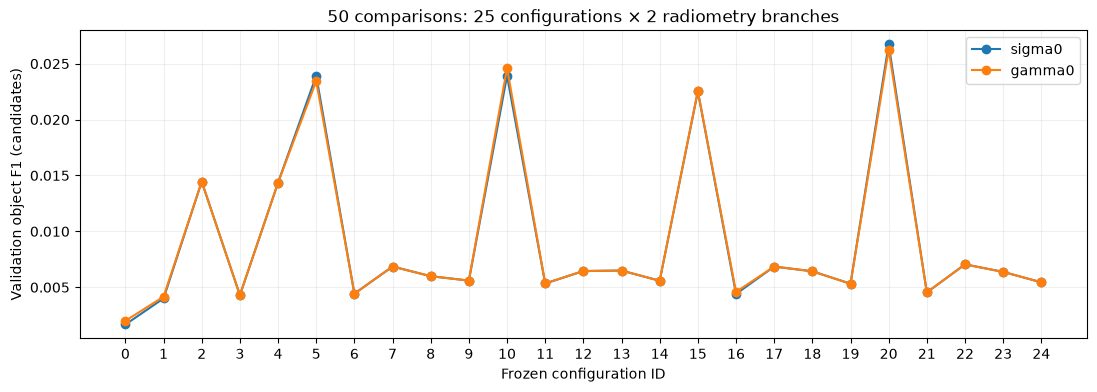

In [3]:
fig, ax = plt.subplots(figsize=(13,4))
for branch in ['sigma0','gamma0']:
    subset = table[table.branch==branch].sort_values('config')
    ax.plot(subset.config, subset.f1, marker='o', label=branch)
ax.set(xlabel='Frozen configuration ID', ylabel='Validation object F1 (candidates)',
       title='50 comparisons: 25 configurations × 2 radiometry branches')
ax.set_xticks(range(25)); ax.legend(); ax.grid(alpha=.2)
plt.show()


## Chạy lại một ví dụ validation, không chọn theo điểm đẹp

Dùng mẫu validation đầu tiên theo ID và cấu hình gamma0 tốt nhất ở bước ứng viên.
Thứ hạng này chưa phản ánh bước SVM/CART. Chuẩn hóa gamma0 hiệu chỉnh diện tích
hình học; không mặc định loại hết ảnh hưởng góc tới lên tán xạ mặt biển.


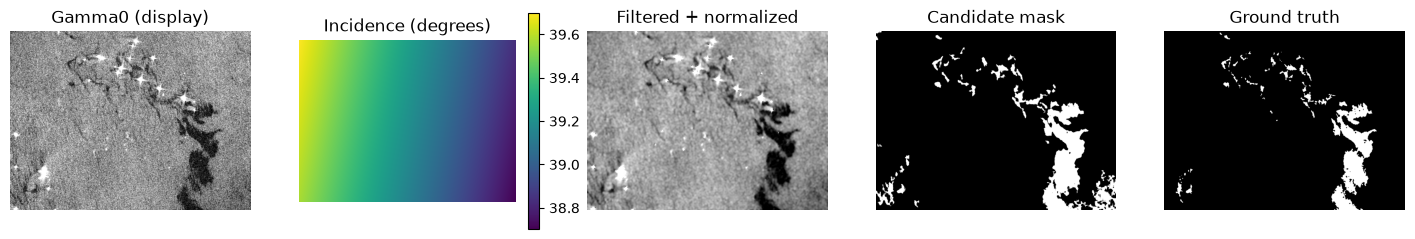

IMG_12_TILE_001 {'id': 20, 'filter': {'name': 'lee', 'size': 7, 'looks': 4}, 'threshold': {'name': 'otsu'}, 'morphology': {'operation': 'none', 'min_area': 64}}
Wind speed (m/s), context only: 3.5119604341420536
Candidate metrics: {'tp': 9, 'fp': 30, 'fn': 64, 'images': 1, 'empty_images': 0, 'intersection': 26603, 'union': 43808, 'predicted_pixels': 43285, 'truth_pixels': 27126, 'edge_gt': 3, 'edge_tp': 0, 'interior_gt': 70, 'interior_tp': 9, 'precision': 0.23076923076923078, 'recall': 0.1232876712328767, 'f1': 0.16071428571428573, 'pixel_iou': 0.6072635135135135, 'dice': 0.7556489753021545, 'fp_per_image': 30.0, 'edge_recall': 0.0, 'interior_recall': 0.12857142857142856}


In [4]:
sample = sorted([r for r in manifest['samples'] if r['split']=='val'], key=lambda r:r['sample'])[0]
ordered = sorted([r for r in screen['comparisons'] if r['branch']=='gamma0'],
                 key=lambda r:(-r['summary']['numpy']['f1'], -r['summary']['numpy']['recall'], r['config_id']))
chosen = ordered[0]
power, truth = load_input(sample, 'gamma0')
outputs = {b:candidates(power, chosen['config'], b) for b in ['numpy','reference']}
stored = next(r for r in chosen['rows'] if r['sample']==sample['sample'])
for backend, output in outputs.items():
    assert counts(output['candidate_mask'], truth) == stored['counts'][backend]
assert np.count_nonzero(outputs['numpy']['candidate_mask'] != outputs['reference']['candidate_mask']) == stored['mask_disagreement_pixels']
raw_display, _ = normalize_power(power)
with np.load(ROOT/sample['file']) as arrays:
    incidence = arrays['incidence_degrees']
fig, axes = plt.subplots(1,5,figsize=(18,4))
for ax, image, title in zip(axes, [raw_display, incidence, outputs['numpy']['image'], outputs['numpy']['candidate_mask'], truth],
                          ['Gamma0 (display)', 'Incidence (degrees)', 'Filtered + normalized', 'Candidate mask', 'Ground truth']):
    plot = ax.imshow(image, cmap='viridis' if title.startswith('Incidence') else 'gray')
    ax.set_title(title); ax.axis('off')
    if title.startswith('Incidence'): fig.colorbar(plot, ax=ax, fraction=.045)
plt.show()
print(sample['sample'], chosen['config'])
print('Wind speed (m/s), context only:', sample['wind_speed_m_s'])
print('Candidate metrics:', summarize([stored['counts']['numpy']]))


## Giới hạn và bước tiếp theo

- Kết quả ứng viên còn thấp; không lựa chọn lại theo test để cải thiện bảng này.
- Tối đa 6 ứng viên/nhánh đi tiếp đến 7 cấu hình SVM/CART mỗi nhánh.
- So sánh NumPy/thư viện kiểm tra thực hiện phép tính; không chứng minh độ chính xác nhãn hay hiệu quả ngoài thực địa.
- Nhãn theo tile có thể đếm lại cùng đối tượng trong một cảnh. Bootstrap cuối phải theo cảnh.
- Dữ liệu chưa hiệu chỉnh thermal noise; đăng ký ảnh vẫn có giới hạn.
- Phải khóa model/selection trước khi đánh giá 25 ảnh test và ablation góc tới.
